# Statistik Təhlil və Kəşfiyyat Xarakterli Məlumat Təhlili (EDA)

#### Kitabxanaları import edek ve sql serverle elaqeni quraq

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "src" / "db.py").exists():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError("src/db.py tapılmadı")
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from src.db import get_engine
from sqlalchemy import text
engine = get_engine()

print("SQL Server bağlantısı hazırdır!")

SQL Server bağlantısı hazırdır!


#### Transaction cədvəlimizi gətirək

In [16]:
silver_transactions_df = pd.read_sql(
    "SELECT * FROM silver.transactions",
    engine
)

print(silver_transactions_df.shape)
display(silver_transactions_df.head())

(77396, 32)


,transaction_id,customer_id,date,time,amount,currency,category,channel,age,gender,...,holiday_name,is_weekend,is_workday,is_pre_holiday,rate_currency,rate_base,rate,temperature_2m_mean,precipitation_sum,wind_speed_10m_max
0,t0040264,c02529,2026-03-27,19:55:59,9.91,azn,alış-veriş,pos,34,qadın,...,əlavə istirahət günü,0,0,0,azn,azn,1.0,10.9,35.5,25.1
1,t0040265,c04195,2026-03-27,19:56:53,794.63,azn,nağdlaşdırma,atm,45,qadın,...,əlavə istirahət günü,0,0,0,azn,azn,1.0,10.9,35.5,25.1
2,t0040266,c03812,2026-03-27,19:57:15,120.90,azn,köçürmə,mobil tətbiq,40,qadın,...,əlavə istirahət günü,0,0,0,azn,azn,1.0,10.9,35.5,25.1
3,t0040267,c00782,2026-03-27,19:57:17,13.81,azn,alış-veriş,pos,48,qadın,...,əlavə istirahət günü,0,0,0,azn,azn,1.0,10.0,14.3,13.8
4,t0040268,c02866,2026-03-27,19:57:21,36.76,azn,alış-veriş,pos,41,qadın,...,əlavə istirahət günü,0,0,0,azn,azn,1.0,13.1,14.3,11.0


#### Bayram və Adi Günlərin Tranzaksiya Davranışına Təsiri

Günləri qruplaşdır
Məqsəd: Bayram günlərinin bank tranzaksiyalarına təsirini araşdırmaq üçün günləri üç qrupa ayırmaq: Holiday, Weekend və Workday.

Metod: is_holiday, is_weekend və is_workday dəyişənlərindən istifadə etməklə np.select() funksiyası vasitəsilə günlər təsnif edilir. Hər qrup üzrə unikal gün sayı hesablanır.

In [17]:
df = silver_transactions_df.copy()
df['date'] = pd.to_datetime(df['date'])

conditions = [
    (df.is_holiday == 1) & (df.is_workday == 0),
    (df.is_holiday == 0) & (df.is_weekend == 1) & (df.is_workday == 0),
    (df.is_holiday == 0) & (df.is_weekend == 0) & (df.is_workday == 1)
]

df['day_type'] = np.select(
    conditions,
    ['Holiday', 'Weekend', 'Workday'],
    default='Other'
)

print(df.groupby('day_type')['date'].nunique())
print(df['currency'].value_counts())

day_type
Holiday     21
Weekend     48
Workday    112
Name: date, dtype: int64
currency
azn    72100
usd     3073
eur     2223
Name: count, dtype: int64


In [18]:
df['amount_azn'] = df['amount'] / df['rate']

print("Ümumi tranzaksiya sayı:", len(df))

display(
    df.groupby('currency')
    .agg(
        count=('transaction_id', 'count'),
        original_amount=('amount', 'sum'),
        amount_azn=('amount_azn', 'sum')
    ).round(2)
)

Ümumi tranzaksiya sayı: 77396


,count,original_amount,amount_azn
currency,,,
azn,72100,6552890.27,6552890.27
eur,2223,101829.74,202053.94
usd,3073,158182.35,268884.53


Gündəlik statistik cədvəl
Gündəlik tranzaksiya göstəriciləri

Məqsəd: Müxtəlif gün tiplərində müştərilərin tranzaksiya aktivliyini müqayisə etmək.

Metod: groupby() və agg() funksiyaları vasitəsilə hər gün üzrə tranzaksiya sayı, ümumi məbləğ və aktiv müştəri sayı hesablanır.

In [19]:
daily_df = (
    df[df['day_type'] != 'Other']
    .groupby(['date', 'day_type'])
    .agg(
        count=('transaction_id', 'count'),
        amount=('amount_azn', 'sum'),
        customers=('customer_id', 'nunique')
    )
    .reset_index()
)



summary = daily_df.groupby('day_type').agg(
    days=('date', 'count'),
    avg_count=('count', 'mean'),
    avg_amount=('amount', 'mean'),
    
).round(2)

display(summary)

,days,avg_count,avg_amount
day_type,,,
Holiday,21,446.76,31892.35
Weekend,48,278.42,21274.51
Workday,112,487.95,47615.30


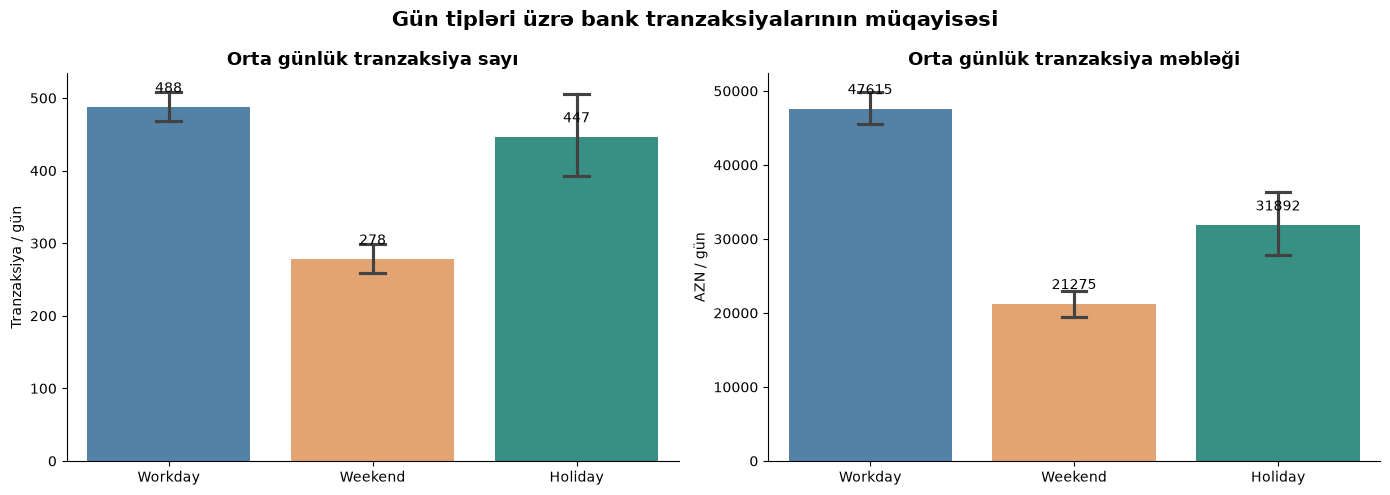

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order = ['Workday', 'Weekend', 'Holiday']
colors = ['#4682B4', '#F4A261', '#2A9D8F']

metrics = [
    ('count', 'Orta günlük tranzaksiya sayı', 'Tranzaksiya / gün'),
    ('amount', 'Orta günlük tranzaksiya məbləği', 'AZN / gün')
]

for ax, (metric, title, ylabel) in zip(axes, metrics):

    sns.barplot(
        data=daily_df,
        x='day_type',
        y=metric,
        order=order,
        hue='day_type',
        hue_order=order,
        palette=colors,
        errorbar=('ci', 95),
        capsize=0.12,
        legend=False,
        ax=ax
    )

    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel(ylabel)

    for container in ax.containers:
        ax.bar_label(container, fmt='%.0f', padding=8)

    ax.spines[['top', 'right']].set_visible(False)

plt.suptitle(
    'Gün tipləri üzrə bank tranzaksiyalarının müqayisəsi',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

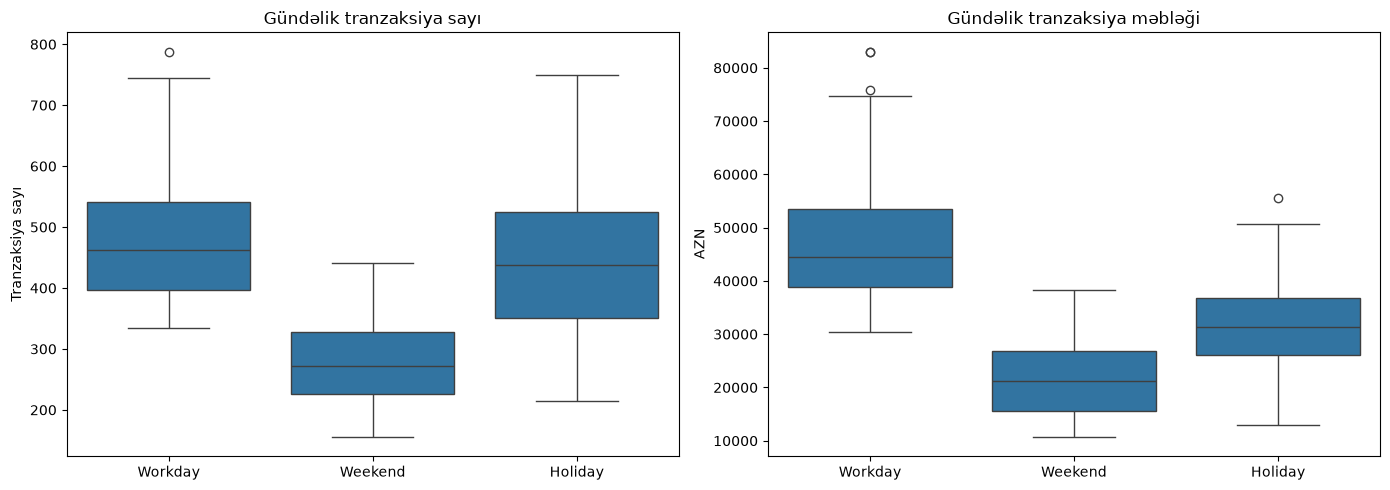

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric, title in zip(
    axes,
    ['count', 'amount'],
    ['Gündəlik tranzaksiya sayı', 'Gündəlik tranzaksiya məbləği']
):
    sns.boxplot(
        data=daily_df,
        x='day_type',
        y=metric,
        order=['Workday', 'Weekend', 'Holiday'],
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel('AZN' if metric == 'amount' else 'Tranzaksiya sayı')

plt.tight_layout()
plt.show()

#### Boxplot analizinə əsasən, iş günlərində tranzaksiya sayı və məbləği daha yüksək, adi həftəsonlarında isə daha aşağıdır.

##### Bayram günlərində tranzaksiya sayının medianı iş günlərinə yaxın olsa da, ümumi tranzaksiya məbləğinin medianı daha aşağıdır.

#### Outlierlerin tƏsirini araşdıraq

In [22]:
for metric in ['count', 'amount']:
    print(f"\n{metric.upper()}")

    for group in ['Holiday', 'Weekend', 'Workday']:
        x = daily_df.loc[daily_df.day_type == group, metric]

        q1 = x.quantile(0.25)
        q3 = x.quantile(0.75)
        iqr = q3 - q1

        clean_x = x[
            (x >= q1 - 1.5 * iqr) &
            (x <= q3 + 1.5 * iqr)
        ]

        print(
            group,
            "| Outlier:", len(x) - len(clean_x),
            "| Original mean:", round(x.mean(), 2),
            "| Without outlier:", round(clean_x.mean(), 2)
        )


COUNT
Holiday | Outlier: 0 | Original mean: 446.76 | Without outlier: 446.76
Weekend | Outlier: 0 | Original mean: 278.42 | Without outlier: 278.42
Workday | Outlier: 1 | Original mean: 487.95 | Without outlier: 485.24

AMOUNT
Holiday | Outlier: 1 | Original mean: 31892.35 | Without outlier: 30706.71
Weekend | Outlier: 0 | Original mean: 21274.51 | Without outlier: 21274.51
Workday | Outlier: 3 | Original mean: 47615.3 | Without outlier: 46707.63


#### Ciddi bir ferq olmadiggi ucun outlierleri kenarlasdirib analiz etmeye ehtiyac yoxdur

In [23]:
from scipy.stats import shapiro

results = []

for metric in ['count', 'amount']:
    for group in ['Holiday', 'Weekend', 'Workday']:

        x = daily_df[daily_df.day_type == group][metric]

        stat, p = shapiro(x)

        results.append({
            'Metric': metric,
            'Group': group,
            'p_value': p,
            'Normal': p >= 0.05
        })

normality_df = pd.DataFrame(results)
display(normality_df.round(4))

,Metric,Group,p_value,Normal
0,count,Holiday,0.9325,True
1,count,Weekend,0.2537,True
2,count,Workday,0.0000,False
3,amount,Holiday,0.8446,True
4,amount,Weekend,0.0643,True
5,amount,Workday,0.0000,False


### Bayram günlərinin tranzaksiya sayı və məbləğinə təsiri — Hipotez testi

**Məqsəd:** Bayram günlərində gündəlik tranzaksiya sayı və ümumi məbləğin adi iş günləri və həftəsonlarından statistik olaraq fərqlənib-fərqlənmədiyini müəyyən etmək.

**Hipotezlər:**
- H₀: Bayram və iş günlərində orta günlük tranzaksiya göstəriciləri bərabərdir.
- H₁: Bayram və iş günlərində orta günlük tranzaksiya göstəriciləri fərqlidir.

**Metod:** Welch's t-test istifadə olunur. Bu test iki qrupun orta göstəricilərini müqayisə edir və dispersiyaların bərabər olmasını tələb etmir. Çoxsaylı testlər üçün Holm düzəlişi tətbiq edilir.

**Əhəmiyyətlilik səviyyəsi:** α = 0.05.

In [24]:
from statsmodels.stats.multitest import multipletests
results = []

for group in ['Weekend', 'Workday']:
    for metric in ['count', 'amount']:

        x = daily_df[daily_df.day_type == 'Holiday'][metric]
        y = daily_df[daily_df.day_type == group][metric]

        t, p = stats.ttest_ind(x, y, equal_var=False)

        results.append({
            'Comparison': f'Holiday vs {group}',
            'Metric': metric,
            'Holiday Mean': x.mean(),
            'Other Mean': y.mean(),
            'Difference %': (x.mean()/y.mean()-1)*100,
            'p_value': p
        })

test_results = pd.DataFrame(results)

test_results['p_adjusted'] = multipletests(
    test_results['p_value'], method='holm'
)[1]

test_results['Significant'] = (
    test_results['p_adjusted'] < 0.05
)

display(test_results.round(4))

,Comparison,Metric,Holiday Mean,Other Mean,Difference %,p_value,p_adjusted,Significant
0,Holiday vs Weekend,count,446.7619,278.4167,60.4652,0.0000,0.0001,True
1,Holiday vs Weekend,amount,31892.3479,21274.5052,49.9088,0.0002,0.0004,True
2,Holiday vs Workday,count,446.7619,487.9464,-8.4404,0.2223,0.2223,False
3,Holiday vs Workday,amount,31892.3479,47615.2963,-33.0208,0.0000,0.0000,True


### Statistik test nəticələrinin interpretasiyası

**1. Bayram günləri və adi həftəsonları**

- **Tranzaksiya sayı:** Bayram günlərində 60.47% yüksəkdir (p_adjusted = 0.0001).
- **Tranzaksiya məbləği:** Bayram günlərində 49.91% yüksəkdir (p_adjusted = 0.0004).

Hər iki göstərici üzrə statistik əhəmiyyətli fərq aşkar edilmişdir (p < 0.05). H₀ hipotezi rədd edilir.

**2. Bayram günləri və iş günləri**

- **Tranzaksiya sayı:** Bayram günlərində 8.44% aşağıdır, lakin fərq statistik əhəmiyyətli deyil (p_adjusted = 0.2223). H₀ rədd edilmir.
- **Tranzaksiya məbləği:** Bayram günlərində 33.02% aşağıdır və fərq statistik əhəmiyyətlidir (p_adjusted < 0.0001). H₀ rədd edilir.

### Əsas biznes insight

Bayram günlərində tranzaksiya sayı iş günlərindən statistik olaraq əhəmiyyətli fərqlənmir, lakin gündəlik tranzaksiya məbləği nəzərəçarpacaq dərəcədə azalır.

Adi həftəsonları ilə müqayisədə isə bayram günlərində həm tranzaksiya sayı, həm də ümumi məbləğ əhəmiyyətli dərəcədə yüksəkdir.

**Nəticə:** Bayram günləri bank əməliyyatlarının aktivliyini tamamilə azaltmır, lakin tranzaksiyaların məbləğ strukturunda dəyişiklik müşahidə olunur. Bu fərqin mümkün səbəblərini müəyyən etmək üçün əməliyyat kateqoriyalarının əlavə təhlili məqsədəuyğundur.

### Kateqoriyalar üzrə gündəlik ortalamaları hesablayaq

In [25]:
# Hər tarix və kateqoriya üzrə göstəricilər
category_daily = (
    df[df['day_type'] != 'Other']
    .groupby(['date', 'day_type', 'category'])
    .agg(
        count=('transaction_id', 'count'),
        amount=('amount_azn', 'sum')
    )
    .reset_index()
)

# Tranzaksiya olmayan günləri də sıfırla nəzərə alırıq
dates = daily_df[['date', 'day_type']].drop_duplicates()
categories = df['category'].dropna().unique()

category_daily = (
    dates.assign(key=1)
    .merge(pd.DataFrame({'category': categories, 'key': 1}), on='key')
    .drop(columns='key')
    .merge(category_daily,
           on=['date', 'day_type', 'category'],
           how='left')
    .fillna({'count': 0, 'amount': 0})
)

category_summary = (
    category_daily
    .groupby(['category', 'day_type'])
    [['count', 'amount']]
    .mean()
    .round(2)
    .reset_index()
)

display(category_summary)

,category,day_type,count,amount
0,alış-veriş,Holiday,186.24,7764.76
1,alış-veriş,Weekend,102.48,4227.88
2,alış-veriş,Workday,157.35,6743.31
3,depozit,Holiday,0.00,0.00
4,depozit,Weekend,0.92,691.15
5,depozit,Workday,9.72,6741.09
6,kredit ödənişi,Holiday,0.00,0.00
7,kredit ödənişi,Weekend,2.02,614.05
8,kredit ödənişi,Workday,19.28,4893.56
9,köçürmə,Holiday,72.62,10012.42


#### Bayram və iş günləri arasındakı faiz fərqini hesablayaq

In [26]:
comparison = category_summary.pivot(
    index='category',
    columns='day_type',
    values=['count', 'amount']
)

category_changes = pd.DataFrame({
    'Count Change %': (
        comparison['count']['Holiday'] /
        comparison['count']['Workday'] - 1
    ) * 100,

    'Amount Change %': (
        comparison['amount']['Holiday'] /
        comparison['amount']['Workday'] - 1
    ) * 100
})

display(category_changes.round(2))

,Count Change %,Amount Change %
category,,
alış-veriş,18.36,15.15
depozit,-100.00,-100.00
kredit ödənişi,-100.00,-100.00
köçürmə,-24.16,-25.14
mobil ödəniş,-5.93,-11.57
nağdlaşdırma,-13.01,-13.01
ödəniş,-4.67,-2.68


Vizual qrafik

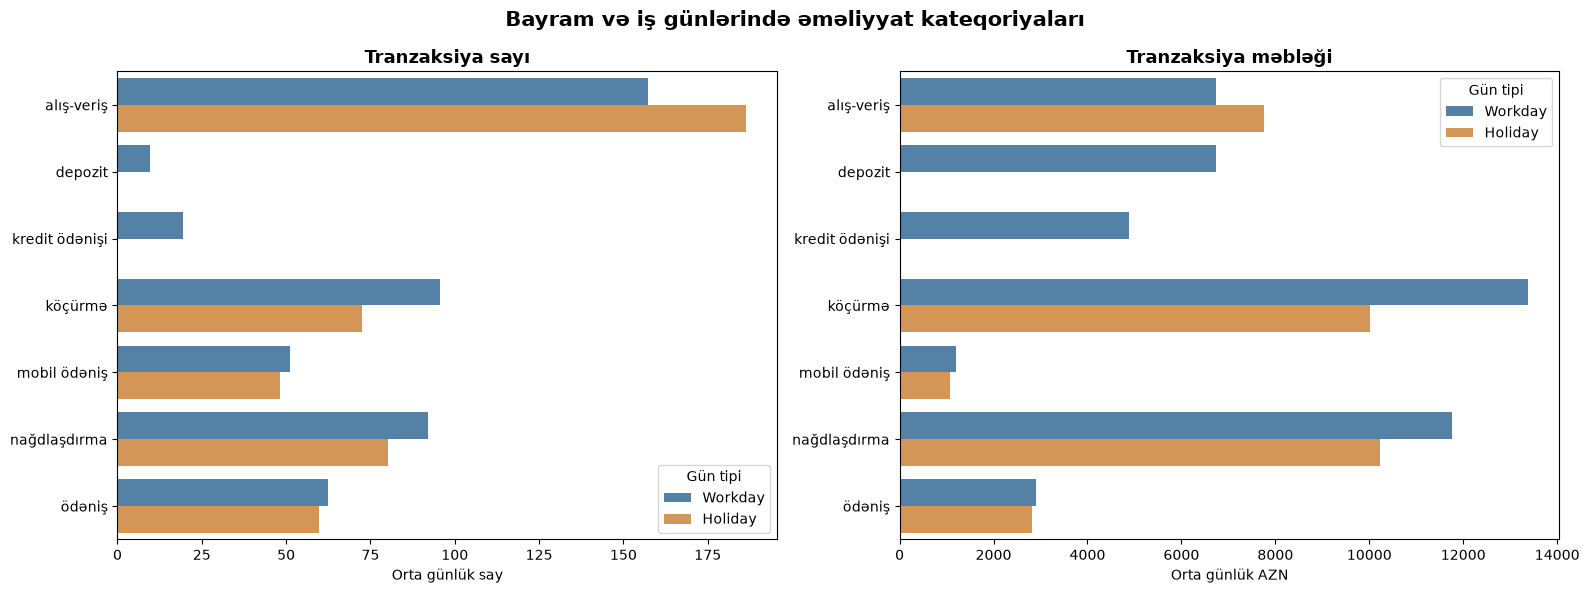

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

data = category_summary[
    category_summary['day_type'].isin(['Holiday', 'Workday'])
]

for ax, metric, title, ylabel in zip(
    axes,
    ['count', 'amount'],
    ['Tranzaksiya sayı', 'Tranzaksiya məbləği'],
    ['Orta günlük say', 'Orta günlük AZN']
):
    sns.barplot(
        data=data,
        y='category',
        x=metric,
        hue='day_type',
        hue_order=['Workday', 'Holiday'],
        palette=['#4682B4', '#E99642'],
        ax=ax
    )

    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel(ylabel)
    ax.set_ylabel('')
    ax.legend(title='Gün tipi')

plt.suptitle(
    'Bayram və iş günlərində əməliyyat kateqoriyaları',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

### Kateqoriyalar üzrə analiz — Nəticə və biznes tövsiyələri

**Nəticə:**

Bayram günlərində alış-veriş tranzaksiyalarının həm sayı, həm də məbləği artır. Bunun əksinə, köçürmə, nağdlaşdırma və mobil ödəniş əməliyyatlarında azalma müşahidə olunur. Depozit və kredit ödənişləri isə bayram günlərində qeydə alınmayıb.

Bu nəticələr bayram günlərində müştərilərin tranzaksiya davranışının dəyişdiyini göstərir. Alış-veriş aktivliyi artsa da, digər maliyyə əməliyyatlarının azalması ümumi tranzaksiya məbləğinin aşağı düşməsi ilə müşayiət olunur.

**Biznes tövsiyələri:**

- **Alış-veriş:** Bayram günlərində artan alış-veriş aktivliyindən yararlanmaq üçün cashback, bonus və POS kampaniyalarının tətbiqi tövsiyə olunur.
- **Kredit və depozit:** Bayram günlərində kredit və depozit əməliyyatları üçün əvvəlcədən planlaşdırılmış avtomatik ödəniş imkanlarının genişləndirilməsi müştəri rahatlığını artıra bilər.
- **Rəqəmsal bankçılıq:** Köçürmə və digər bank əməliyyatlarının mobil bankçılıq vasitəsilə həyata keçirilməsini təşviq edən kampaniyalar tətbiq edilə bilər.

**Əsas insight:** Bayram günlərində müştərilərin bank aktivliyi daha çox alış-veriş əməliyyatlarına yönəlir. Bu davranış bank üçün bayram dövrlərində kart istifadəsini artırmağa və müştəri aktivliyini dəstəkləməyə yönəlmiş kampaniyalar hazırlamaq imkanı yaradır.

## Maaş dövrünün tranzaksiya davranışına təsiri

### 1. Maaş dövrünün müəyyənləşdirilməsi

**Məqsəd:** Ehtimal olunan maaş dövründə müştərilərin gündəlik tranzaksiya sayı və məbləğinin digər günlərdən fərqlənib-fərqlənmədiyini araşdırmaq.

**Metod:** Ayın 1–5-i və 25-dən sonrakı günlər ehtimal olunan maaş dövrü kimi müəyyən edilir. Digər tarixlər müqayisə qrupu kimi istifadə olunur.

Analiz gündəlik tranzaksiya sayı və AZN-ə çevrilmiş ümumi tranzaksiya məbləği əsasında aparılır.

In [28]:
salary_daily = daily_df.copy()

# Ayın günü
salary_daily['day_of_month'] = salary_daily['date'].dt.day

# Ehtimal olunan maaş dövrü
salary_daily['salary_period'] = np.where(
    (salary_daily['day_of_month'] <= 5) |
    (salary_daily['day_of_month'] >= 25),
    'Salary Period',
    'Other Days'
)

# Günlərin sayı və orta göstəricilər
salary_summary = (
    salary_daily.groupby('salary_period')
    .agg(
        days=('date', 'count'),
        avg_count=('count', 'mean'),
        avg_amount=('amount', 'mean')
    )
    .round(2)
)

display(salary_summary)

,days,avg_count,avg_amount
salary_period,,,
Other Days,114,386.92,35466.10
Salary Period,67,496.82,44487.96


#### Maaş dövrünə düşən günlərin çoxu iş günü, yaxud həftəsonu ola bilər. Ona görə bu bölgünü də görək:

In [29]:
display(
    pd.crosstab(
        salary_daily['salary_period'],
        salary_daily['day_type']
    )
)

day_type,Holiday,Weekend,Workday
salary_period,,,
Other Days,11,29,74
Salary Period,10,19,38


#### Maaş dövrü kimi seçilmiş tarixlərdə bank aktivliyi daha yüksəkdir. Lakin bunun statistik əhəmiyyətini hələ yoxlamamışıq.hər iki qrupda bayram, həftəsonu və iş günləri var. Buna görə maaş dövrünün təsirini ayrıca qiymətləndirərkən gün tipini nəzərə almaq vacibdir.

#### Vizualizasiya və outlier analizi

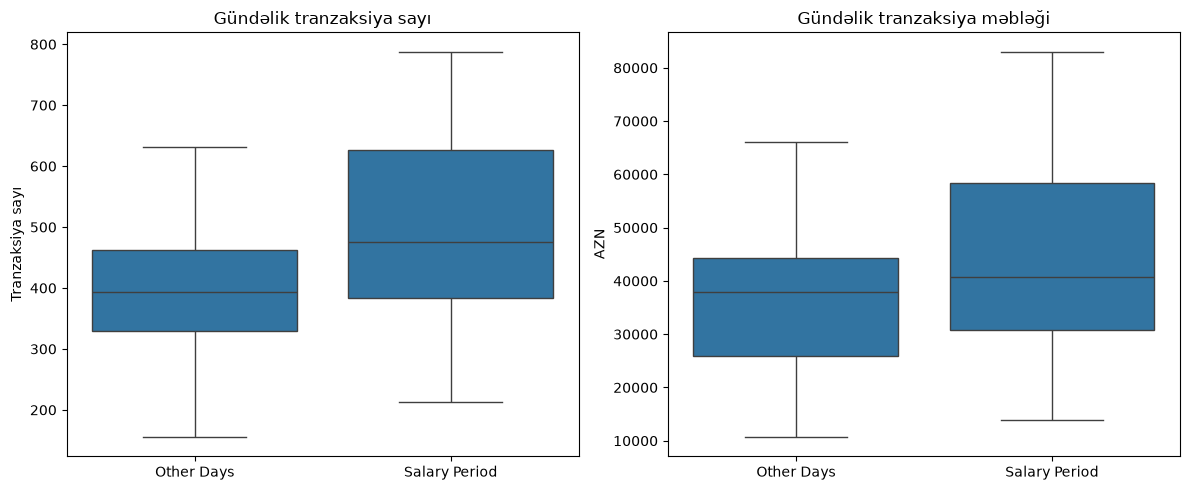

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, metric, title in zip(
    axes,
    ['count', 'amount'],
    ['Gündəlik tranzaksiya sayı',
     'Gündəlik tranzaksiya məbləği']
):
    sns.boxplot(
        data=salary_daily,
        x='salary_period',
        y=metric,
        order=['Other Days', 'Salary Period'],
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel('AZN' if metric == 'amount' else 'Tranzaksiya sayı')

plt.tight_layout()
plt.show()

### Boxplot nəticələri

Maaş dövründə həm gündəlik tranzaksiya sayı, həm də məbləği digər günlərdən daha yüksəkdir.

Bu dövrdə göstəricilər günlər üzrə daha çox dəyişir.

Qrafikdə outlier müşahidə olunmur.

**Nəticə:** Maaş dövründə bank əməliyyatları daha aktivdir. Bu fərqin statistik olaraq əhəmiyyətli olub-olmadığını hipotez testi ilə yoxlayacağıq.

### Normal paylanmanın yoxlanılması — Shapiro–Wilk testi

**Məqsəd:** Maaş dövrü və digər günlərdə tranzaksiya sayı və məbləğinin normal paylanmaya uyğunluğunu yoxlamaq.

**Hipotezlər:**
- H₀: Məlumatlar normal paylanmadan gəlir.
- H₁: Məlumatlar normal paylanmadan gəlmir.

**Metod:** Shapiro–Wilk testi tətbiq edilir. Əhəmiyyətlilik səviyyəsi α = 0.05 qəbul olunur.

Testin nəticələri əsas statistik müqayisə metodunun seçilməsində nəzərə alınacaq.

In [31]:
from scipy.stats import shapiro

results = []

for metric in ['count', 'amount']:
    for group in ['Salary Period', 'Other Days']:

        x = salary_daily.loc[
            salary_daily['salary_period'] == group, metric
        ]

        stat, p = shapiro(x)

        results.append({
            'Metric': metric,
            'Group': group,
            'p_value': p,
            'Normal': p >= 0.05
        })

salary_normality = pd.DataFrame(results)
display(salary_normality.round(4))

,Metric,Group,p_value,Normal
0,count,Salary Period,0.0195,False
1,count,Other Days,0.0147,False
2,amount,Salary Period,0.1294,True
3,amount,Other Days,0.0192,False


### Normalıq testinin nəticəsi

Shapiro–Wilk testinə görə tranzaksiya sayı hər iki qrupda normal paylanmır.

Tranzaksiya məbləği isə maaş dövründə normal paylanmadan ciddi fərqlənmir, digər günlərdə isə fərqlənir.

Qruplarda kifayət qədər müşahidə olduğu üçün ortalamaları Welch t-test ilə müqayisə edəcəyik.

### Hipotez testi — Welch t-test

### Maaş dövrünün tranzaksiya sayı və məbləğinə təsiri — Hipotez testi

**Məqsəd:** Maaş dövründə tranzaksiya sayı və məbləğinin digər günlərdən fərqlənib-fərqlənmədiyini yoxlamaq.

**Hipotezlər:**
- H₀: Maaş dövrü ilə digər günlərin orta göstəriciləri eynidir.
- H₁: Maaş dövrü ilə digər günlərin orta göstəriciləri fərqlidir.

**Metod:** Welch t-test istifadə edilir. Əhəmiyyətlilik səviyyəsi 0.05-dir.

In [32]:
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

results = []

for metric in ['count', 'amount']:

    x = salary_daily[
        salary_daily['salary_period'] == 'Salary Period'
    ][metric]

    y = salary_daily[
        salary_daily['salary_period'] == 'Other Days'
    ][metric]

    t, p = ttest_ind(x, y, equal_var=False)

    results.append({
        'Metric': metric,
        'Salary Mean': x.mean(),
        'Other Mean': y.mean(),
        'Difference %': (x.mean() / y.mean() - 1) * 100,
        'p_value': p
    })

salary_tests = pd.DataFrame(results)

salary_tests['p_adjusted'] = multipletests(
    salary_tests['p_value'],
    method='holm'
)[1]

salary_tests['Significant'] = salary_tests['p_adjusted'] < 0.05

display(salary_tests.round(4))

,Metric,Salary Mean,Other Mean,Difference %,p_value,p_adjusted,Significant
0,count,496.8209,386.9211,28.4037,0.0000,0.0000,True
1,amount,44487.9604,35466.0999,25.4380,0.0005,0.0005,True


#### Hər iki göstərici üzrə statistik əhəmiyyətli fərq tapdıq. Yəni maaş dövrü kimi seçdiyimiz tarixlərdə bank aktivliyi digər günlərdən yüksəkdir.

## Məzənnənin tranzaksiya sayı və məbləği ilə əlaqəsi.

#### Gündəlik məzənnə cədvəlini yaradaq

## Məzənnənin bank tranzaksiyalarına təsirinin analizi

### 1. Gündəlik məzənnə məlumatlarının hazırlanması

**Məqsəd:** USD və EUR məzənnələrinin dəyişməsi ilə bankın gündəlik tranzaksiya sayı və məbləği arasında əlaqə olub-olmadığını araşdırmaq.

**Metod:** Hər gün üçün USD və EUR məzənnələri götürülür və gündəlik tranzaksiya göstəriciləri ilə birləşdirilir.

In [33]:
# USD və EUR məzənnələrini seçirik
rates = df[
    df['rate_currency'].str.lower().isin(['usd', 'eur'])
].copy()

rates['rate_currency'] = rates['rate_currency'].str.lower()

# Hər gün və valyuta üçün məzənnə
daily_rates = (
    rates.groupby(['date', 'rate_currency'])['rate']
    .median()
    .unstack()
    .rename(columns={
        'usd': 'usd_rate',
        'eur': 'eur_rate'
    })
    .reset_index()
)

# Gündəlik tranzaksiya cədvəli ilə birləşdiririk
fx_daily = daily_df.merge(
    daily_rates,
    on='date',
    how='left'
).sort_values('date')

display(fx_daily.head())
print(fx_daily[['usd_rate', 'eur_rate']].isna().sum())

,date,day_type,count,amount,customers,eur_rate,usd_rate
0,2026-01-01,Holiday,623,43359.991432,571,0.50084,0.58837
1,2026-01-02,Holiday,750,55605.069187,686,0.50095,0.58830
2,2026-01-03,Weekend,322,28117.890687,310,0.50107,0.58837
3,2026-01-04,Weekend,226,15942.634611,217,0.50114,0.58838
4,2026-01-05,Workday,722,82965.803090,665,0.50266,0.58812


usd_rate    0
eur_rate    0
dtype: int64


### 2. Məzənnələrin dəyişməsinin yoxlanılması

**Məqsəd:** USD və EUR məzənnələrinin analiz dövründə necə dəyişdiyini görmək.

**Metod:** Məzənnələrin minimum, maksimum, orta qiymətləri və standart kənarlaşması hesablanır. Dəyişikliklər xətt qrafiki ilə göstərilir.

Bu nəticələr əsasında məzənnə ilə tranzaksiyalar arasında əlaqəni araşdıracağıq.

In [34]:
display(
    fx_daily[['usd_rate', 'eur_rate']]
    .agg(['count', 'min', 'max', 'mean', 'std'])
    .round(5)
)

,usd_rate,eur_rate
count,181.00000,181.00000
min,0.58746,0.49161
max,0.58887,0.51773
mean,0.58830,0.50428
std,0.00022,0.00544


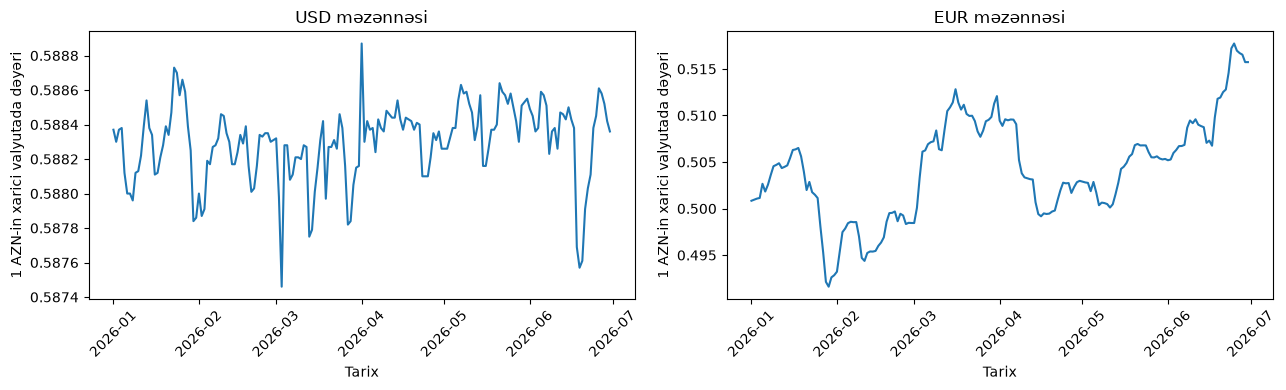

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, col, title in zip(
    axes,
    ['usd_rate', 'eur_rate'],
    ['USD məzənnəsi', 'EUR məzənnəsi']
):
    sns.lineplot(
        data=fx_daily,
        x='date',
        y=col,
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel('Tarix')
    ax.set_ylabel('1 AZN-in xarici valyutada dəyəri')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

#### Nəticələrə baxanda:
- USD: Demək olar sabitdir (standart kənarlaşma 0.00022).
- EUR: Nisbətən daha çox dəyişir (standart kənarlaşma 0.00544).
- Hər iki valyuta üzrə 181 günlük məlumatımız var.
Qərar: USD-də dəyişiklik çox az olduğu üçün əsas diqqəti EUR məzənnəsinə yönəldək. USD-ni də müqayisə üçün saxlayaq.


### Məzənnə ilə tranzaksiyalar arasında əlaqə —Spearman Korrelyasiya testi

**Məqsəd:** USD və EUR məzənnələri ilə gündəlik tranzaksiya sayı və məbləği arasında əlaqə olub-olmadığını yoxlamaq.

**Hipotezlər:**
- H₀: Məzənnə ilə tranzaksiya göstəriciləri arasında monoton əlaqə yoxdur.
- H₁: Məzənnə ilə tranzaksiya göstəriciləri arasında monoton əlaqə var.

**Metod:** Spearman korrelyasiya testi istifadə edilir. Bu test göstəricilərin normal paylanmasını tələb etmir.

Əhəmiyyətlilik səviyyəsi 0.05-dir.

In [36]:
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

results = []

for rate in ['usd_rate', 'eur_rate']:
    for metric in ['count', 'amount']:

        data = fx_daily[[rate, metric]].dropna()

        rho, p = spearmanr(data[rate], data[metric])

        results.append({
            'Currency': rate,
            'Metric': metric,
            'Correlation': rho,
            'p_value': p
        })

fx_tests = pd.DataFrame(results)

fx_tests['p_adjusted'] = multipletests(
    fx_tests['p_value'],
    method='holm'
)[1]

fx_tests['Significant'] = fx_tests['p_adjusted'] < 0.05

display(fx_tests.round(4))

,Currency,Metric,Correlation,p_value,p_adjusted,Significant
0,usd_rate,count,-0.0483,0.5181,0.9932,False
1,usd_rate,amount,-0.0509,0.4966,0.9932,False
2,eur_rate,count,-0.2192,0.0030,0.0091,True
3,eur_rate,amount,-0.2387,0.0012,0.0048,True


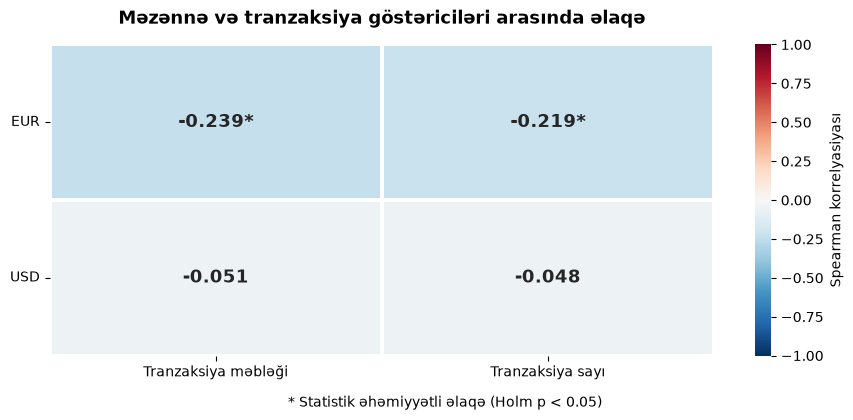

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

# Korrelyasiya cədvəli
heatmap_data = fx_tests.pivot(
    index='Currency',
    columns='Metric',
    values='Correlation'
)

# Statistik əhəmiyyətlilik
significance = fx_tests.pivot(
    index='Currency',
    columns='Metric',
    values='Significant'
)

# Hüceyrələrdə göstəriləcək yazılar
labels = heatmap_data.copy().astype(str)

for row in heatmap_data.index:
    for col in heatmap_data.columns:
        value = heatmap_data.loc[row, col]
        star = '*' if significance.loc[row, col] else ''
        labels.loc[row, col] = f'{value:.3f}{star}'

# Sütun adları
heatmap_data = heatmap_data.rename(columns={
    'count': 'Tranzaksiya sayı',
    'amount': 'Tranzaksiya məbləği'
})

labels = labels.rename(columns={
    'count': 'Tranzaksiya sayı',
    'amount': 'Tranzaksiya məbləği'
})

heatmap_data.index = ['EUR', 'USD'] if list(heatmap_data.index) == ['eur_rate', 'usd_rate'] else heatmap_data.index
labels.index = heatmap_data.index

# Heatmap
plt.figure(figsize=(9, 4))

sns.heatmap(
    heatmap_data,
    annot=labels,
    fmt='',
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=1.5,
    linecolor='white',
    annot_kws={'size': 13, 'weight': 'bold'},
    cbar_kws={'label': 'Spearman korrelyasiyası'}
)

plt.title(
    'Məzənnə və tranzaksiya göstəriciləri arasında əlaqə',
    fontsize=13,
    fontweight='bold',
    pad=15
)

plt.xlabel('')
plt.ylabel('')
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.figtext(
    0.5, -0.03,
    '* Statistik əhəmiyyətli əlaqə (Holm p < 0.05)',
    ha='center',
    fontsize=10
)

plt.tight_layout()
plt.show()

### Korrelyasiya nəticələrinin heatmap ilə göstərilməsi

Heatmap USD və EUR məzənnələrinin tranzaksiya sayı və məbləği ilə əlaqəsini göstərir.

- **Mənfi qiymətlər:** Əks istiqamətli əlaqə.
- **0-a yaxın qiymətlər:** Çox zəif əlaqə.
- **(*) işarəsi:** Statistik əhəmiyyətli əlaqə (p < 0.05).

**Nəticə:** EUR məzənnəsi ilə hər iki tranzaksiya göstəricisi arasında zəif mənfi əlaqə var. USD üzrə isə statistik əhəmiyyətli əlaqə tapılmayıb.

## Hava temperaturunun bank tranzaksiyaları ilə əlaqəsi

### Gündəlik temperatur məlumatlarının hazırlanması

**Məqsəd:** Hava temperaturu ilə gündəlik tranzaksiya sayı və məbləği arasında əlaqə olub-olmadığını araşdırmaq.

**Metod:** Hər günün orta temperaturu götürülür və gündəlik tranzaksiya göstəriciləri ilə birləşdirilir.

In [38]:
# Hər tarix üçün orta temperatur
daily_weather = (
    df.groupby('date')
    .agg(
        temperature=('temperature_2m_mean', 'mean')
    )
    .reset_index()
)

# Tranzaksiya göstəriciləri ilə birləşdiririk
weather_daily = daily_df.merge(
    daily_weather,
    on='date',
    how='left'
)

display(weather_daily.head())

# Temperatur statistikası
display(
    weather_daily['temperature']
    .describe()
    .round(2)
)

,date,day_type,count,amount,customers,temperature
0,2026-01-01,Holiday,623,43359.991432,571,4.062921
1,2026-01-02,Holiday,750,55605.069187,686,2.727200
2,2026-01-03,Weekend,322,28117.890687,310,1.388820
3,2026-01-04,Weekend,226,15942.634611,217,2.379204
4,2026-01-05,Workday,722,82965.803090,665,5.697645


count    181.00
mean      12.25
std        7.04
min        0.72
25%        6.48
50%       11.47
75%       18.36
max       27.88
Name: temperature, dtype: float64

### Temperatur və tranzaksiyalar arasında əlaqənin yoxlanılması

**Məqsəd:** Temperatur artdıqda və ya azaldıqda gündəlik tranzaksiya sayı və məbləğinin necə dəyişdiyini öyrənmək.

**Metod:** Scatterplot ilə əlaqəni qrafikdə göstəririk. Spearman testi ilə əlaqənin gücünü və statistik əhəmiyyətini yoxlayırıq.

**Hipotezlər:**
- H₀: Temperatur ilə tranzaksiya göstəriciləri arasında monoton əlaqə yoxdur.
- H₁: Temperatur ilə tranzaksiya göstəriciləri arasında monoton əlaqə var.

Əhəmiyyətlilik səviyyəsi: 0.05.

#### Scatterplot qrafikləri

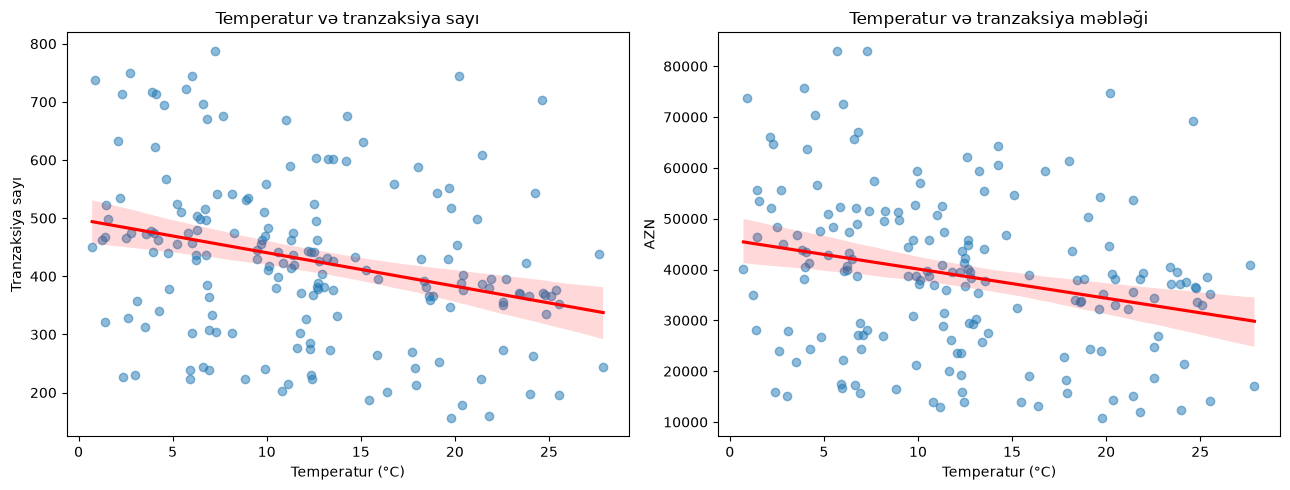

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, metric, title in zip(
    axes,
    ['count', 'amount'],
    ['Temperatur və tranzaksiya sayı',
     'Temperatur və tranzaksiya məbləği']
):
    sns.regplot(
        data=weather_daily,
        x='temperature',
        y=metric,
        scatter_kws={'alpha': 0.5},
        line_kws={'color': 'red'},
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel('Temperatur (°C)')
    ax.set_ylabel('AZN' if metric == 'amount' else 'Tranzaksiya sayı')

plt.tight_layout()
plt.show()

#### Spearman korrelyasiya testi

In [40]:
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

results = []

for metric in ['count', 'amount']:

    data = weather_daily[['temperature', metric]].dropna()

    rho, p = spearmanr(
        data['temperature'],
        data[metric]
    )

    results.append({
        'Metric': metric,
        'Correlation': rho,
        'p_value': p
    })

weather_tests = pd.DataFrame(results)

weather_tests['p_adjusted'] = multipletests(
    weather_tests['p_value'],
    method='holm'
)[1]

display(weather_tests.round(4))

,Metric,Correlation,p_value,p_adjusted
0,count,-0.3145,0.0000,0.0000
1,amount,-0.2812,0.0001,0.0001


### Temperatur və tranzaksiyalar — Qrafikin şərhi

Scatterplot qrafiklərinə əsasən, temperatur artdıqca gündəlik tranzaksiya sayı və məbləği azalmağa meyillidir.

Hər iki qrafikdə qırmızı xəttin aşağı istiqamətdə olması mənfi əlaqəni göstərir. Lakin nöqtələrin geniş yayılması bu əlaqənin güclü olmadığını göstərir.

Spearman testi də bu nəticəni təsdiqləyir:
- **Tranzaksiya sayı:** ρ = -0.3145
- **Tranzaksiya məbləği:** ρ = -0.2812

Hər iki əlaqə statistik olaraq əhəmiyyətlidir (p < 0.05).

**Nəticə:** Temperatur yüksək olan günlərdə bank əməliyyatlarının sayı və məbləği daha aşağı olmağa meyillidir. Lakin bu fərqə mövsümilik və digər faktorlar da təsir edə bilər.

### Ayların və gün tiplərinin nəzərə alınması

**Məqsəd:** Temperaturla tranzaksiyalar arasındakı əlaqənin aylar və gün tipləri nəzərə alındıqdan sonra da davam edib-etmədiyini yoxlamaq.

**Metod:** OLS regressiya modeli istifadə edilir. Modelə temperatur, aylar və gün tipləri daxil edilir.

In [41]:
import statsmodels.formula.api as smf

weather_daily['month'] = weather_daily['date'].dt.month

for metric in ['count', 'amount']:
    model = smf.ols(
        f'{metric} ~ temperature + C(month) + C(day_type)',
        data=weather_daily
    ).fit(
        cov_type='HAC',
        cov_kwds={'maxlags': 7}
    )

    print(f"\n{metric.upper()}")
    print("Temperatur əmsalı:", round(model.params['temperature'], 2))
    print("p-value:", round(model.pvalues['temperature'], 4))


COUNT
Temperatur əmsalı: -3.96
p-value: 0.1636

AMOUNT
Temperatur əmsalı: -299.84
p-value: 0.241


### Temperatur analizinin yekun nəticəsi

İlkin Spearman testində temperaturla tranzaksiya sayı və məbləği arasında mənfi, statistik əhəmiyyətli əlaqə tapılmışdı.

Lakin aylar və gün tipləri nəzərə alınaraq regressiya testi aparıldıqda:

- Tranzaksiya sayı: p = 0.1636
- Tranzaksiya məbləği: p = 0.2410

Hər iki halda p > 0.05 olduğu üçün statistik əhəmiyyətli əlaqə tapılmadı.

**Nəticə:** Temperaturla tranzaksiya aktivliyi arasında ilkin müşahidə etdiyimiz mənfi əlaqə mövsümilik və gün tipləri ilə bağlı ola bilər.

**Biznes tövsiyəsi:** Bank tranzaksiya aktivliyini qiymətləndirərkən yalnız temperatura əsaslanmamalı, ayları, bayramları və iş günlərini də nəzərə almalıdır.

## Faktorların birlikdə analizi — Çoxdəyişənli regressiya

### Məlumatların hazırlanması

**Məqsəd:** Bayram, maaş dövrü, məzənnə və temperaturun tranzaksiya sayı və məbləği ilə əlaqəsini birlikdə yoxlamaq.

**Metod:** Multiple Linear Regression (OLS) istifadə edirik. Ayları və gün tiplərini də nəzərə alırıq.

İki model quracağıq:
- Gündəlik tranzaksiya sayı
- Gündəlik tranzaksiya məbləği (AZN)

In [42]:
# Əvvəlki cədvəlləri birləşdiririk
reg_df = (
    salary_daily[
        ['date', 'day_type', 'salary_period', 'count', 'amount']
    ]
    .merge(
        fx_daily[['date', 'eur_rate']],
        on='date',
        how='left'
    )
    .merge(
        weather_daily[['date', 'temperature']],
        on='date',
        how='left'
    )
)

reg_df['date'] = pd.to_datetime(reg_df['date'])
reg_df['month'] = reg_df['date'].dt.month

reg_df['is_salary_period'] = (
    reg_df['salary_period'] == 'Salary Period'
).astype(int)

# EUR məzənnəsini mərkəzləşdiririk
reg_df['eur_centered'] = (
    reg_df['eur_rate'] - reg_df['eur_rate'].mean()
)

reg_df = reg_df.sort_values('date').dropna()

print("Müşahidə sayı:", len(reg_df))
display(reg_df.head())

Müşahidə sayı: 181


,date,day_type,salary_period,count,amount,eur_rate,temperature,month,is_salary_period,eur_centered
0,2026-01-01,Holiday,Salary Period,623,43359.991432,0.50084,4.062921,1,1,-0.003444
1,2026-01-02,Holiday,Salary Period,750,55605.069187,0.50095,2.727200,1,1,-0.003334
2,2026-01-03,Weekend,Salary Period,322,28117.890687,0.50107,1.388820,1,1,-0.003214
3,2026-01-04,Weekend,Salary Period,226,15942.634611,0.50114,2.379204,1,1,-0.003144
4,2026-01-05,Workday,Salary Period,722,82965.803090,0.50266,5.697645,1,1,-0.001624


### Regressiya modellərinin qurulması

**Məqsəd:** Digər faktorlar nəzərə alındıqdan sonra hansı göstəricilərin tranzaksiya sayı və məbləği ilə statistik əlaqəsinin qaldığını müəyyən etmək.

**Hipotezlər:**
- H₀: Faktorun regressiya əmsalı sıfırdır.
- H₁: Faktorun regressiya əmsalı sıfırdan fərqlidir.

**Metod:** OLS regressiyası istifadə edilir. Günlər arasında mümkün zaman asılılığını nəzərə almaq üçün HAC standart xətaları tətbiq olunur.

Əhəmiyyətlilik səviyyəsi: 0.05.

In [43]:
import statsmodels.formula.api as smf

formula = """
{target} ~ C(day_type, Treatment(reference='Workday'))
+ is_salary_period
+ temperature
+ eur_centered
+ C(month)
"""

model_count = smf.ols(
    formula.format(target='count'),
    data=reg_df
).fit(cov_type='HAC', cov_kwds={'maxlags': 7})

model_amount = smf.ols(
    formula.format(target='amount'),
    data=reg_df
).fit(cov_type='HAC', cov_kwds={'maxlags': 7})

In [44]:
reg_results = pd.DataFrame({
    'Factor': model_count.params.index,
    'Count Effect': model_count.params.values,
    'Count p-value': model_count.pvalues.values,
    'Amount Effect (AZN)': model_amount.params.values,
    'Amount p-value': model_amount.pvalues.values
})

display(reg_results.round(4))

print("Count R²:", round(model_count.rsquared, 3))
print("Amount R²:", round(model_amount.rsquared, 3))

,Factor,Count Effect,Count p-value,Amount Effect (AZN),Amount p-value
0,Intercept,507.8294,0.0000,49739.0064,0.0000
1,"C(day_type, Treatment(reference='Workday'))[T....",-53.4651,0.0212,-16810.1072,0.0000
2,"C(day_type, Treatment(reference='Workday'))[T....",-217.5811,0.0000,-27099.9673,0.0000
3,C(month)[T.2],10.3011,0.5390,845.0895,0.6487
4,C(month)[T.3],-63.3489,0.0000,-6719.5432,0.0000
5,C(month)[T.4],-85.6309,0.0002,-8991.5272,0.0001
6,C(month)[T.5],-86.5977,0.0065,-9287.5298,0.0024
7,C(month)[T.6],-114.0993,0.0066,-12418.4293,0.0028
8,is_salary_period,121.0079,0.0000,10933.3278,0.0000
9,temperature,-0.3203,0.8824,25.8020,0.9025


Count R²: 0.696
Amount R²: 0.746


### Çoxdəyişənli regressiya — Nəticələr

**Məqsəd:** Bayram, maaş dövrü, temperatur və məzənnənin tranzaksiyalarla əlaqəsini digər faktorları da nəzərə alaraq yoxlamaq.

**Nəticələr:**

- Maaş dövründə gündəlik tranzaksiya sayı orta hesabla 121, məbləğ isə 10,933 AZN daha yüksəkdir.
- Bayram günlərində iş günlərinə nisbətən tranzaksiya sayı 53, məbləğ isə 16,810 AZN aşağıdır.
- Həftəsonlarında həm tranzaksiya sayı, həm də məbləğ daha aşağıdır.
- Temperatur və EUR məzənnəsi üzrə statistik əhəmiyyətli əlaqə tapılmadı.

**Modelin nəticələri:**
- Tranzaksiya sayı: R² = 0.696
- Tranzaksiya məbləği: R² = 0.746

**Əsas insight:** Bank tranzaksiyaları ilə ən güclü əlaqə maaş dövrü və gün tiplərində müşahidə olunur. Temperatur və EUR məzənnəsinin əlaqəsi isə digər faktorlar nəzərə alındıqda statistik əhəmiyyətli deyil.

**Biznes tövsiyələri:**
- Maaş dövründə artan əməliyyat aktivliyinə uyğun bank xidmətlərinin hazırlığı gücləndirilə bilər.
- Bayram və həftəsonlarında müştəri davranışına uyğun kart və mobil bankçılıq kampaniyaları tətbiq edilə bilər.
- Tranzaksiya aktivliyinin planlaşdırılmasında maaş dövrü, bayram və həftəsonu göstəricilərinə üstünlük verilə bilər.